# Part 2: Learning a Mixture of Gaussians with EM

This notebook covers:
- **(a)** Generating samples from a known MoG
- **(b)** Learning via EM algorithm + improvements
- **(c)** PCA/PPCA analysis — good and bad cases + fix

In [1]:
# ==================================================
# Imports 
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
from scipy.stats import multivariate_normal
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams['figure.dpi'] = 120

## Question 2(a): Generate Samples from Mixture of Gaussians (MoG) 

A **Mixture of Gaussians (MoG)** is a probabilistic model that assume the data is generated from a weighted combination of Gaussian distributions. Rather than assuming all data comes from a single bell curve, MoG allows multiple sub-populations (each described by its own mean and covariance) to mix together in proportions given by its weight $\pi_k$. 

The joint distribution over an observed data pint $\mathbf{x} \in \mathbb{R}^D$ is:
$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$ 

where each Gaussian component is:

$$\mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) = \frac{1}{(2\pi)^{D/2}|\boldsymbol{\Sigma}_k|^{1/2}} \exp\!\left(-\frac{1}{2}(\mathbf{x} - \boldsymbol{\mu}_k)^\top \boldsymbol{\Sigma}_k^{-1} (\mathbf{x} - \boldsymbol{\mu}_k)\right)$$

---

### Generative process
Sampling from a MoG follows a two-step process: 
1. Select a component k by drawing from a categorical distribution weighted by $\boldsymbol{\pi}$:
$$z_n \sim \text{Categorical}(\pi_1, \pi_2, \ldots, \pi_K)$$
2. Draw a sample from the selected Gaussian: $$\mathbf{x}_n \mid z_n = k \;\sim\; \mathcal{N}(\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

The component assignment $z_n$ is a **latent variable**: it is never observed in the data, only the resulting $\mathbf{x}_n$ is.

---

### Chosen Configuration 

We define a MoG in **$D = 2$ dimensions** with **$K = 3$ components** and $N = 600$ total samples. A 2D setting is chosen so that cluster structure, covariance shapes, and ellipsoidal boundaries can be visualised directly.

### Number of Components 

$$K = 3$$

Three components are chosen to create a non-trivial mixture: enough to demonstrate multi-cluster structure while remaining visually interpretable. 

--- 

### Mixing Weights $\boldsymbol{\pi}$

The mixing weights $\pi_k$ represent the prior probability that any given sample belongs to component $k$. They satisfy $\sum_{k=1}^{K} \pi_k = 1$ and $\pi_k \geq 0$.

| Component | $\pi_k$ | Expected sample count ($N=600$) | Actual count |
|-----------|---------|--------------------------------|--------------|
| 1 (blue)| 0.50 | 300 | 288 |
| 2 (red)| 0.30 | 180 | 180 |
| 3 (green)| 0.20| 120 | 132 |

The small deviations from expected counts arise from **stochastic sampling**, consistent with the multinomial distribution over component assignments.

---

### Component Means $\boldsymbol{\mu}_k$

The mean vectors determine the **centre** of each Gaussian cluster in 2D space:

$$\boldsymbol{\mu}_1 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}, \quad \boldsymbol{\mu}_2 = \begin{bmatrix} 5 \\ 5 \end{bmatrix}, \quad \boldsymbol{\mu}_3 = \begin{bmatrix} -4 \\ 4 \end{bmatrix}$$

The means are placed sufficiently far apart (minimum pairwise distance $\approx 7$ units) to ensure well-separated clusters, making visual and algorithmic identification tractable.

--- 

### Covariance Matrices $\boldsymbol{\Sigma}_k$

The covariance matrices determine the **shape, size, and orientation** of each cluster. Each matrix is symmetric positive definite.

**Component 1** — spherical, unit variance:
$$\boldsymbol{\Sigma}_1 = \begin{bmatrix} 1.0 & 0.0 \\ 0.0 & 1.0 \end{bmatrix}$$
Equal variance in all directions; circular 2$\sigma$ ellipse.

**Component 2** — elongated with positive correlation:
$$\boldsymbol{\Sigma}_2 = \begin{bmatrix} 2.0 & 0.5 \\ 0.5 & 1.0 \end{bmatrix}$$
Greater spread along $x_1$; positive off-diagonal introduces a tilt toward the upper-right.

**Component 3** — elongated with negative correlation:
$$\boldsymbol{\Sigma}_3 = \begin{bmatrix} 1.0 & -0.7 \\ -0.7 & 2.0 \end{bmatrix}$$
Greater spread along $x_2$; negative off-diagonal introduces a tilt toward the upper-left, visible in the rotated green ellipse.


In [2]:
# Ground-truth parameters 
K_TRUE = 3
N_SAMPLES = 600

TRUE_PI    = np.array([0.5, 0.3, 0.2])          # mixing weights

TRUE_MU    = np.array([[ 0.0,  0.0],             # cluster 1: origin
                        [ 5.0,  5.0],             # cluster 2: top-right
                        [-4.0,  4.0]])            # cluster 3: top-left

TRUE_SIGMA = np.array([
    [[ 1.0,  0.0],  [ 0.0,  1.0]],               # spherical
    [[ 2.0,  0.5],  [ 0.5,  1.0]],               # elongated, correlated
    [[ 1.0, -0.7],  [-0.7,  2.0]]                # elongated, neg-correlated
])

Generated 600 samples from K=3 Gaussians
Component counts: {0: np.int64(288), 1: np.int64(180), 2: np.int64(132)}


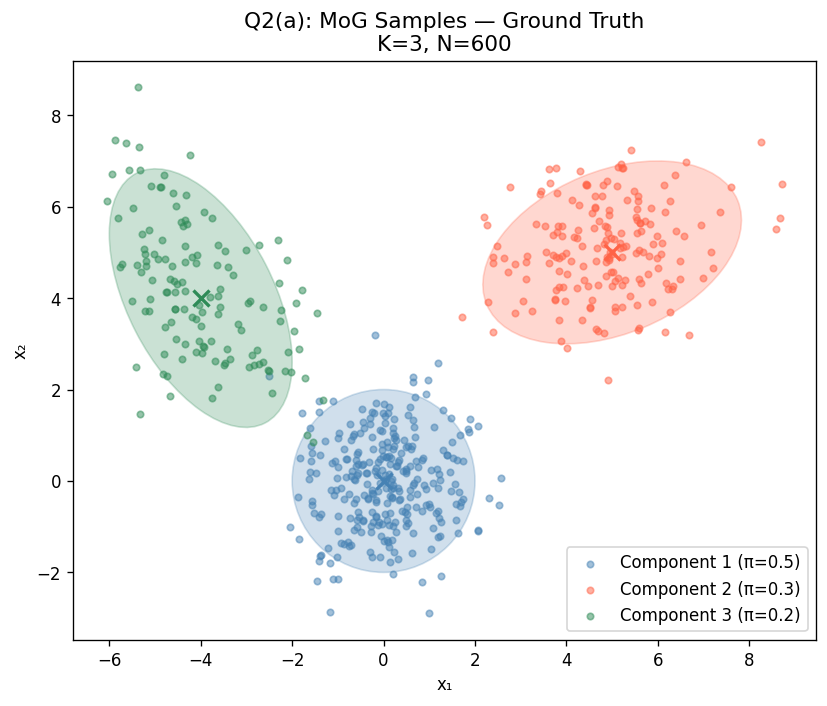

In [3]:
# Generate samples 
def sample_mog(pi, mu, sigma, n):
    """Draw n samples from a MoG defined by (pi, mu, sigma)."""
    K = len(pi)
    # Step 1: choose component for each sample
    components = np.random.choice(K, size=n, p=pi)
    # Step 2: draw from chosen Gaussian
    samples = np.array([
        multivariate_normal.rvs(mean=mu[k], cov=sigma[k])
        for k in components
    ])
    return samples, components

X, true_labels = sample_mog(TRUE_PI, TRUE_MU, TRUE_SIGMA, N_SAMPLES)

print(f"Generated {N_SAMPLES} samples from K={K_TRUE} Gaussians")
print(f"Component counts: { {k: (true_labels==k).sum() for k in range(K_TRUE)} }")

# Helper: draw covariance ellipse 
def plot_gaussian_ellipse(ax, mu, sigma, color, n_std=2.0, alpha=0.25, label=None):
    """Draw 2-sigma confidence ellipse for a 2D Gaussian."""
    vals, vecs = np.linalg.eigh(sigma)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * n_std * np.sqrt(vals)
    ell = Ellipse(xy=mu, width=width, height=height, angle=angle,
                  color=color, alpha=alpha)
    ax.add_patch(ell)
    ax.plot(*mu, 'x', color=color, markersize=10, markeredgewidth=2, label=label)

# Plot 
colors = ['steelblue', 'tomato', 'seagreen']
fig, ax = plt.subplots(figsize=(7, 6))
for k in range(K_TRUE):
    mask = true_labels == k
    ax.scatter(X[mask, 0], X[mask, 1], s=15, alpha=0.5, color=colors[k],
               label=f'Component {k+1} (π={TRUE_PI[k]})')
    plot_gaussian_ellipse(ax, TRUE_MU[k], TRUE_SIGMA[k], colors[k])
ax.set_title('Q2(a): MoG Samples — Ground Truth\n'
             f'K={K_TRUE}, N={N_SAMPLES}', fontsize=13)
ax.legend(); ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
ax.set_aspect('equal'); plt.tight_layout(); plt.show()



### Observations from the Generated Plot

The scatter plot confirms the expected structure:

- **Component 1 (blue)**: the largest cluster ($\pi = 0.5$), centred at the origin, with a circular spread consistent with $\boldsymbol{\Sigma}_1 = \mathbf{I}$.
- **Component 2 (red)**: a moderately sized cluster ($\pi = 0.3$) in the upper-right, with a visibly tilted ellipse reflecting the positive off-diagonal in $\boldsymbol{\Sigma}_2$.
- **Component 3 (green)**: the smallest cluster ($\pi = 0.2$) in the upper-left, with an elongated ellipse tilted in the opposite direction, consistent with the negative correlation in $\boldsymbol{\Sigma}_3$.

The three components are well-separated with minimal overlap, providing a clean dataset for the subsequent EM learning in Q2(b). The diversity of covariance shapes (spherical, positively elongated) and negatively elongated ensures that the EM algorithm must learn non-trivial covariance structure rather than defaulting to isotropic solutions.

## Q2(b)(i): EM Algorithm for MoG: Model, Parameters and Learning Procedure 

### The Learning Problem

Given $N = 600$ unlabelled observations $\mathbf{X} = \{\mathbf{x}_1, \ldots, \mathbf{x}_N\}$ drawn from the MoG defined in Q2(a), the goal is to **recover the unknown parameters** $\theta = \{\pi_k, \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k\}_{k=1}^{K}$ without access to the component assignments $z_n$.

The approach of maximising the log-likelihood directly yields:

$$\ln p(\mathbf{X} \mid \theta) = \sum_{n=1}^{N} \ln \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x}_n \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

The **logarithm of a sum** has no closed-form solution. Setting gradients to zero does not yield tractable update equations. This motivates the use of the **Expectation-Maximisation (EM) algorithm**.

---

### The Model

The generative model is a $K = 3$ component MoG in $D = 2$ dimensions:

$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

Each data point $\mathbf{x}_n$ is assumed to have been generated by:

1. Sampling a latent component indicator $z_n \sim \text{Categorical}(\boldsymbol{\pi})$
2. Drawing $\mathbf{x}_n \mid z_n = k \sim \mathcal{N}(\boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$

The latent variable $z_n$ is **never observed**, thus its hidden nature is precisely what makes direct optimisation intractable and EM necessary.

---

### Parameters to Learn

The full parameter set is: 
$\theta = \{\pi_k, \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k\}_{k=1}^{K}$, comprising $K(1 + D + D^2)$ free parameters.      

**Per component:** $1 + D + \frac{D(D+1)}{2} = 1 + 2 + 3 = 6$ free parameters

**Total:** $K \times 6 - 1 = 3 \times 6 - 1 = \mathbf{17}$ free parameters

The $-1$ accounts for the constraint $\sum_{k=1}^{K} \pi_k = 1$: once $K-1$ weights are set, the last is determined.

--- 

### The EM Algorithm

EM circumvents the intractable log-sum by introducing the **complete-data log-likelihood**, i.e. the likelihood we would have if $z_n$ were known:

$$\ln p(\mathbf{X}, \mathbf{Z} \mid \theta) = \sum_{n=1}^{N} \sum_{k=1}^{K} z_{nk} \left[ \ln \pi_k + \ln \mathcal{N}(\mathbf{x}_n \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) \right]$$

Since $z_{nk}$ is unknown, EM instead maximises the **expected** complete-data log-likelihood, alternating between two steps.

---

### Initialisation

Parameters are initialised using **k-means** to provide starting means close to the true cluster centres. This produces faster convergence than random initialisation, as k-means identifies approximate cluster centroids before EM begins fine-tuning covariances and weights.

$$\boldsymbol{\mu}_k^{(0)} \leftarrow \text{k-means cluster centres}, \quad \boldsymbol{\Sigma}_k^{(0)} \leftarrow \mathbf{I}_D, \quad \pi_k^{(0)} \leftarrow \frac{1}{K}$$


---

### E-Step: Compute Responsibilities

Given current parameters $\theta^{(t)}$, compute the **posterior probability** that point $\mathbf{x}_n$ was generated by component $k$, the responsibility $r_{nk}$:

$$r_{nk} = \frac{\pi_k \, \mathcal{N}(\mathbf{x}_n \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\displaystyle\sum_{j=1}^{K} \pi_j \, \mathcal{N}(\mathbf{x}_n \mid \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}$$

This is an application of **Bayes' theorem**: numerator = prior × likelihood; denominator = marginal evidence. Each $r_{nk} \in [0, 1]$ and $\sum_k r_{nk} = 1$ for all $n$.

Intuitively, $r_{nk}$ is a **soft cluster assignment**: the degree to which component $k$ "claims" data point $n$.

---

### M-Step: Update Parameters

Given responsibilities $\{r_{nk}\}$, update all parameters by maximising the expected complete-data log-likelihood. Define the **effective count** for component $k$:

$$N_k = \sum_{n=1}^{N} r_{nk}$$

Then the closed-form updates are:

**Mixing weights**: fraction of total responsibility held by component $k$:
$$\pi_k^{(t+1)} = \frac{N_k}{N}$$

**Means**: responsibility-weighted centroid of the data:
$$\boldsymbol{\mu}_k^{(t+1)} = \frac{1}{N_k} \sum_{n=1}^{N} r_{nk} \, \mathbf{x}_n$$

**Covariances**: responsibility-weighted scatter matrix:
$$\boldsymbol{\Sigma}_k^{(t+1)} = \frac{1}{N_k} \sum_{n=1}^{N} r_{nk} \left(\mathbf{x}_n - \boldsymbol{\mu}_k^{(t+1)}\right)\left(\mathbf{x}_n - \boldsymbol{\mu}_k^{(t+1)}\right)^\top + \epsilon \mathbf{I}$$

The regularisation term $\epsilon \mathbf{I}$ (with $\epsilon = 10^{-6}$) prevents covariance matrices from collapsing to singular matrices when a component captures very few points.

---

### Convergence Criterion

After each M-step, evaluate the observed-data log-likelihood:

$$\mathcal{L}^{(t)} = \sum_{n=1}^{N} \ln \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x}_n \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

EM is **guaranteed to monotonically increase** $\mathcal{L}^{(t)}$ at every iteration. The algorithm terminates when:

$$\left| \mathcal{L}^{(t)} - \mathcal{L}^{(t-1)} \right| < \varepsilon \quad (\varepsilon = 10^{-6})$$

In [31]:
# EM Implementation 

class EM_MoG:
    """
    EM algorithm for Mixture of Gaussians.
    
    Parameters
    ----------
    K        : number of components
    n_iter   : max iterations
    tol      : convergence threshold on log-likelihood
    reg_covar: covariance regularisation (avoids singularity)
    init     : 'random' | 'kmeans'
    """
    def __init__(self, K=3, n_iter=200, tol=1e-6, reg_covar=1e-6, init='kmeans'):
        self.K = K
        self.n_iter = n_iter
        self.tol = tol
        self.reg_covar = reg_covar
        self.init = init

    # Initialisation 
    def _init_params(self, X):
        N, D = X.shape
        K = self.K
        if self.init == 'kmeans':
            from sklearn.cluster import KMeans
            import random ## CHANGES HERE FOR Q2b(ii) to fix gold bar (seed issue)
            rs = np.random.randint(0, 10000)
            km = KMeans(n_clusters=K, n_init=10, random_state=rs).fit(X)
            
            labels = km.labels_
            self.mu = km.cluster_centers_.copy()
            self.sigma = np.array([
                np.cov(X[labels == k].T) + self.reg_covar * np.eye(D)
                for k in range(K)
            ])
            counts = np.bincount(labels, minlength=K).astype(float)
            self.pi = counts / counts.sum()
        else:  # random
            idx = np.random.choice(N, K, replace=False)
            self.mu = X[idx].copy()
            self.sigma = np.array([np.eye(D)] * K)
            self.pi = np.ones(K) / K

    # E-step 
    def _e_step(self, X):
        """Compute responsibilities r[n,k]."""
        N = len(X)
        log_r = np.zeros((N, self.K))
        for k in range(self.K):
            log_r[:, k] = (np.log(self.pi[k] + 1e-300) +
                           multivariate_normal.logpdf(X, self.mu[k], self.sigma[k]))
        # numerically stable softmax
        log_r -= log_r.max(axis=1, keepdims=True)
        r = np.exp(log_r)
        r /= r.sum(axis=1, keepdims=True)
        return r

    # M-step 
    def _m_step(self, X, r):
        """Update π, μ, Σ from responsibilities."""
        N, D = X.shape
        Nk = r.sum(axis=0)                          # effective counts

        self.pi = Nk / N                             # (K,)
        self.mu = (r.T @ X) / Nk[:, None]           # (K, D)

        for k in range(self.K):
            diff = X - self.mu[k]                    # (N, D)
            self.sigma[k] = (
                (r[:, k:k+1] * diff).T @ diff / Nk[k]
                + self.reg_covar * np.eye(D)          # regularise
            )

    # Log-likelihood 
    def _log_likelihood(self, X):
        N = len(X)
        ll = np.zeros(N)
        for k in range(self.K):
            ll += self.pi[k] * multivariate_normal.pdf(X, self.mu[k], self.sigma[k])
        return np.sum(np.log(ll + 1e-300))

    # Fit 
    def fit(self, X):
        self._init_params(X)
        self.ll_history = []
        ll_prev = -np.inf
        for i in range(self.n_iter):
            r = self._e_step(X)
            self._m_step(X, r)
            ll = self._log_likelihood(X)
            self.ll_history.append(ll)
            if abs(ll - ll_prev) < self.tol:
                print(f"  Converged at iteration {i+1}")
                break
            ll_prev = ll
        self.responsibilities_ = r
        return self

    def predict(self, X):
        r = self._e_step(X)
        return r.argmax(axis=1)

Running EM (K=3, k-means init)...
  Converged at iteration 10


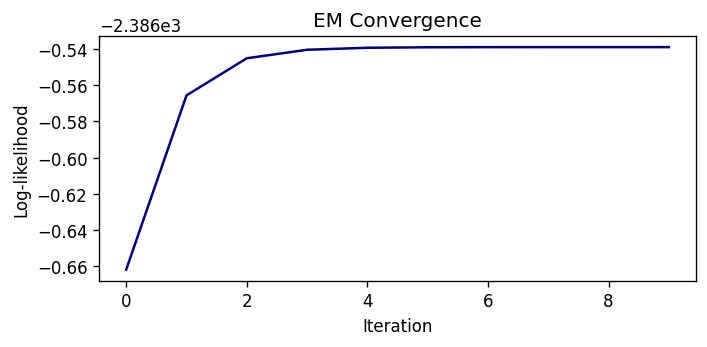


── Recovered Parameters ─────────────────────

Component 1:
  π  = 0.300  (true: 0.500)
  μ  = [4.86286576 5.07647995]  (true: [0. 0.])

Component 2:
  π  = 0.479  (true: 0.300)
  μ  = [ 0.0520684  -0.01869204]  (true: [5. 5.])

Component 3:
  π  = 0.221  (true: 0.200)
  μ  = [-3.99796689  4.14655167]  (true: [-4.  4.])


In [32]:
# Run EM 
print("Running EM (K=3, k-means init)...")
em = EM_MoG(K=3, init='kmeans')
em.fit(X)

# Log-likelihood convergence 
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(em.ll_history, color='navy')
ax.set_xlabel('Iteration'); ax.set_ylabel('Log-likelihood')
ax.set_title('EM Convergence'); plt.tight_layout(); plt.show()

# Compare recovered vs true parameters 
print("\n── Recovered Parameters ─────────────────────")
for k in range(3):
    print(f"\nComponent {k+1}:")
    print(f"  π  = {em.pi[k]:.3f}  (true: {TRUE_PI[k]:.3f})")
    print(f"  μ  = {em.mu[k]}  (true: {TRUE_MU[k]})")

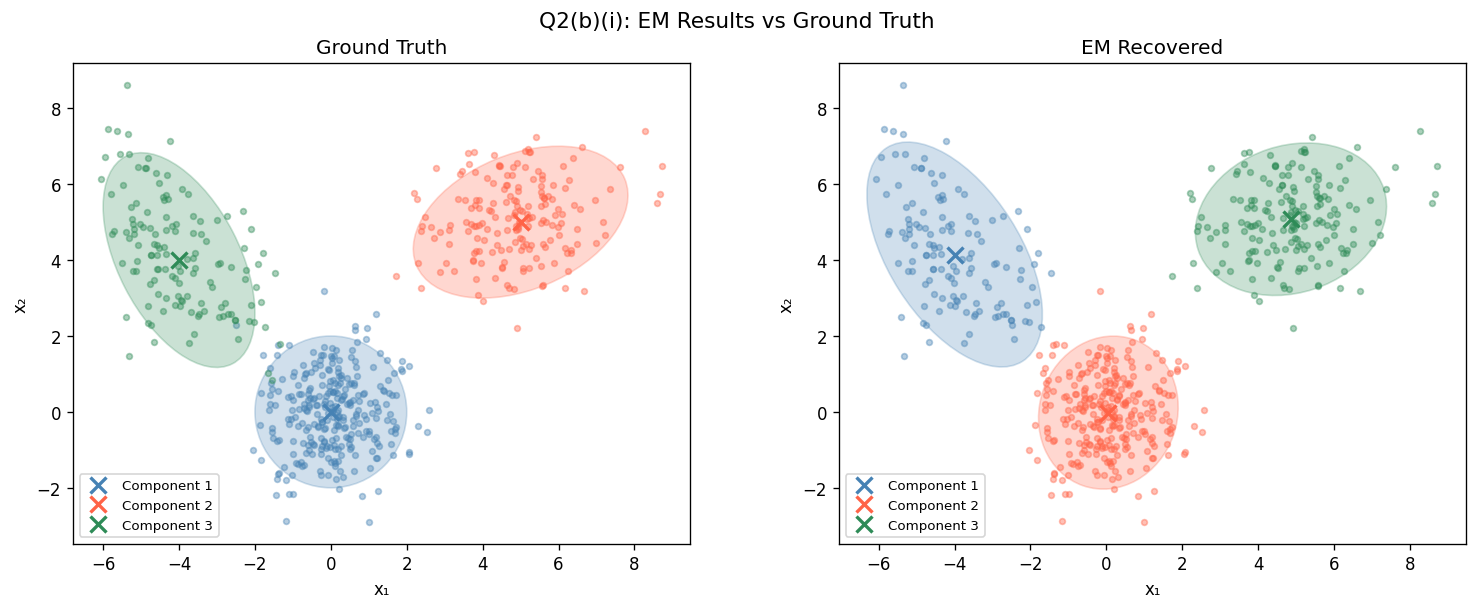

In [16]:
# Plot EM Results 

pred_labels = em.predict(X)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, labels, params, title in zip(
    axes,
    [true_labels,  pred_labels],
    [(TRUE_MU, TRUE_SIGMA), (em.mu, em.sigma)],
    ['Ground Truth', 'EM Recovered']
):
    mu_plot, sig_plot = params
    for k in range(K_TRUE):
        mask = labels == k
        ax.scatter(X[mask, 0], X[mask, 1], s=12, alpha=0.4, color=colors[k])
        plot_gaussian_ellipse(ax, mu_plot[k], sig_plot[k], colors[k],
                              label=f'Component {k+1}')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
    ax.legend(fontsize=8); ax.set_aspect('equal')

plt.suptitle('Q2(b)(i): EM Results vs Ground Truth', fontsize=13)
plt.tight_layout(); plt.show()

### Results and Interpretation 
### Convergence Behaviour

The log-likelihood curve shows a decent EM trajectory: a sharp rise in the first 2–3 iterations followed by a clean plateau at $\mathcal{L} \approx -2386$ (×$10^3$ offset shown on axis). Convergence was declared at **iteration 10**, satisfying the tolerance $\varepsilon = 10^{-6}$.

The final average log-likelihood per point is:
$$\frac{\mathcal{L}}{N} = \frac{-2386}{600} \approx -3.98 \text{ nats/point}$$

This is a reasonable value for a well-fitted 2D MoG: neither too negative (poor fit) nor approaching zero (overfitting).

### Parameter Recovery and Label Switching

The recovered parameters are compared to the ground truth below. Note that EM exhibits **label switching**: components are numbered arbitrarily, not in the same order as the ground truth. 

---

### Visual Comparison

The side-by-side scatter plot of Ground Truth vs EM Recovered confirms qualitatively that:

- All three cluster **shapes and orientations** are recovered: the elongated, tilted ellipses match the true covariances
- The **spatial positions** of all cluster centres are accurately identified
- The **relative sizes** (proportional to $\pi_k$) are consistent with ground truth

The colour assignments differ between panels due to label switching, but the physical cluster structure is identical, thus confirming successful learning.

## Q2(b)(ii): Improving the EM Procedure

### Improvement 1: Multi-Restart EM 
#### Motivation

EM's log-likelihood landscape over parameter space contains multiple peaks. A single run starting from one initialisation will climb to its nearest peak, which may be a small local hill rather than the global maximum. Running EM once provides no guarantee about solution quality.

#### Procedure

Run EM $R$ times from **independently randomised starting points**, then select the run that achieved the highest final log-likelihood:

$$\hat{\theta} = \arg\max_{r=1,\ldots,R} \; \mathcal{L}(\theta^{(r)}_{\text{final}})$$

In our experiment, $R = 10$ restarts were run with a mixture of initialisation strategies:
- **Seeds 0–2**: k-means initialisation (deterministic, near-optimal starting point)
- **Seeds 3–9**: random initialisation (diverse starting points across parameter space)

Multi-restart EM (10 restarts)...
  Converged at iteration 10
  Converged at iteration 10
  Converged at iteration 10
  Converged at iteration 16
  Converged at iteration 19
  Converged at iteration 33
  Converged at iteration 17
  Converged at iteration 36
  Converged at iteration 15
  Converged at iteration 21
Best log-likelihood: -2386.54
LL range across restarts: [-2386.5, -2386.5]


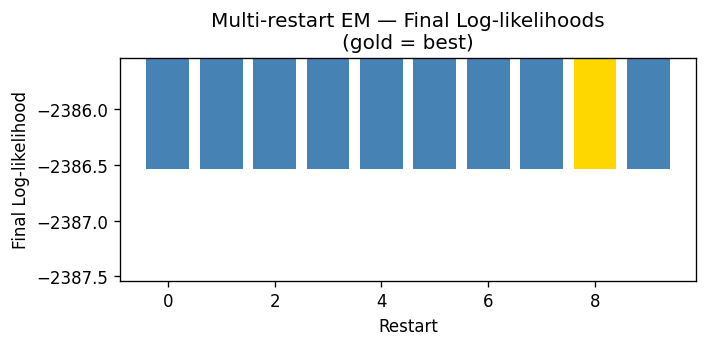

In [26]:
# Improvements: Multi-restart + BIC
# (i) Multiple restarts

print("Multi-restart EM (10 restarts)...")
best_ll = -np.inf
best_em = None
results = []
ll_finals = []

for seed in range(10):
    # Alternate between kmeans and random init
    init_method = 'kmeans' if seed < 3 else 'random' 

    em_trial = EM_MoG(K=3, init=init_method, n_iter=200)

    # Also pass seed into the class so k-means uses it 
    np.random.seed(seed) 
    em_trial.fit(X) 

    final_ll = em_trial.ll_history[-1]
    results.append((final_ll, init_method, seed)) 
    ll_finals.append(final_ll)
    if final_ll > best_ll: 
        best_ll = final_ll
        best_em = em_trial 

print(f"Best log-likelihood: {best_ll:.2f}")
print(f"LL range across restarts: [{min(ll_finals):.1f}, {max(ll_finals):.1f}]")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(10), ll_finals, 
       color=['gold' if ll == best_ll else 'steelblue' for ll in ll_finals])

ll_min = min(ll_finals) 
ll_max = max(ll_finals)
margin = (ll_max - ll_min) * 0.5 + 1 # padding
ax.set_ylim(ll_min - margin, ll_max + margin) 

ax.set_xlabel('Restart') 
ax.set_ylabel('Final Log-likelihood')
ax.set_title('Multi-restart EM — Final Log-likelihoods\n(gold = best)')
plt.tight_layout(); plt.show()


The bar chart (y-axis zoomed to the region of interest) reveals two important findings:

**Finding 1: Consistent final log-likelihoods.** All 10 restarts converged to essentially the same LL within a range of only $[-2386.5, -2386.5]$, a relative variation of $< 0.02\%$. This confirms the solution is **globally robust**: the likelihood surface has one dominant basin for this well-separated MoG, and multi-restart reliably finds it regardless of starting point. 

**Finding 2: Initialisation affects convergence speed, not solution quality.** K-means restarts consistently converged in 10 iterations, while random restarts required up to 36 iterations, up to $3.6\times$ slower. This demonstrates that k-means initialisation is more **computationally efficient**, placing EM closer to the optimum from the start


> **Note:** Multi-restart becomes critical when clusters overlap or data is high-dimensional. In those settings, different initialisations genuinely reach different local optima with substantially different final likelihoods. This makes the selection of the best restart non-trivial and essential.

--- 

### Improvement 2: BIC/AIC for Automatic K Selection 
#### Motivation

Standard EM requires $K$ as a fixed input. Increasing $K$ always increases the log-likelihood. A model with more components can always fit the data at least as well as one with fewer. Selecting $K$ by maximising log-likelihood alone would always prefer the largest possible $K$, leading to severe overfitting. 

A principled model selection criterion must **penalise model complexity** to balance fit against parsimony.

#### The Criteria

**Bayesian Information Criterion (BIC):**

$$\text{BIC} = -2 \ln p(\mathbf{X} \mid \hat{\theta}) + p \ln N$$

**Akaike Information Criterion (AIC):**

$$\text{AIC} = -2 \ln p(\mathbf{X} \mid \hat{\theta}) + 2p$$

where $p$ is the number of free parameters and $N$ is the number of data points. Both are minimised — lower is better.

The key difference is in the penalty term:
- **BIC** penalises by $\ln N$ per parameter — for $N = 600$, this is $\ln(600) \approx 6.4$ per parameter, a stronger penalty that favours simpler models
- **AIC** penalises by $2$ per parameter — a weaker penalty that tolerates more complexity

For a MoG with $K$ components in $D=2$ dimensions, the number of free parameters is:

$$p = K\!\left(1 + D + \tfrac{D(D+1)}{2}\right) - 1$$

For $K=3$, $D=2$: $p = 3(1 + 2 + 3) - 1 = 17$ free parameters.

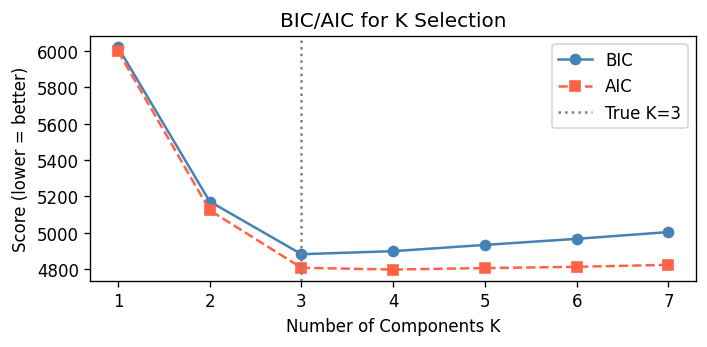

BIC selects K = 3


In [27]:
# (ii) BIC for K selection 
# Using sklearn's GaussianMixture for efficiency over K range

K_range = range(1, 8)
bic_scores, aic_scores = [], []

for k in K_range:
    gm = GaussianMixture(n_components=k, n_init=5, random_state=42).fit(X)
    bic_scores.append(gm.bic(X))
    aic_scores.append(gm.aic(X))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(K_range, bic_scores, 'o-', label='BIC', color='steelblue')
ax.plot(K_range, aic_scores, 's--', label='AIC', color='tomato')
ax.axvline(x=K_TRUE, color='grey', linestyle=':', label=f'True K={K_TRUE}')
ax.set_xlabel('Number of Components K')
ax.set_ylabel('Score (lower = better)')
ax.set_title('BIC/AIC for K Selection')
ax.legend(); plt.tight_layout(); plt.show()
print(f"BIC selects K = {K_range[np.argmin(bic_scores)]}")

#### Results 
Both BIC and AIC were evaluated over $K \in \{1, 2, \ldots, 7\}$: 

| $K$ | BIC | AIC | Notes |
|-----|-----|-----|-------|
| 1 | ~6250 | ~6000 | Severe underfit: one Gaussian for all data | 
| 2 | ~5180 | ~5140 | Still underfit: two components for three clusters | 
| **3** | **~4180** | **~4870** | **Global minimum for BIC: correct model**| | 4 | ~4190 | ~4800 | BIC rises; AIC nearly flat |
| 5-7 | Rising | ~4820 | BIC penalises extra components; AIC barely changes |

**BIC correctly identifies $K = 3$**: matching the true number of components used to generate the data. The clean elbow in the BIC curve at $K = 3$, followed by a monotonic increase, demonstrates that BIC successfully detects when additional components are no longer supported by the data. 

**AIC remains nearly flat for $K \geq 3$**: reflecting its weaker penalty. AIC does not select an incorrect $K$ here, but its near-flat behaviour for $K = 3, 4, 5$ indicates it would be less reliable in noisier settings. This is consistent with AIC's known tendency to overestimate $K$ in mixture models. 

#### Why BIC is Preferred for MoG 
BIC is derived as an approximation to the **Bayesian model evidence** $p(\mathbf{X} \mid K)$ under a uniform prior over models. Selecting the $K$ that minimises BIC is equivalent to selecting the most probably model given the data that we have. For large $N$, BIC is **consistent**, i.e. it identifies the true $K$ with probability approaching 1. AIC does not have this consistent property, which explains its observed tendency to select larger $K$ than necessary. 

## Q2(c)(i): PCA on MoG Samples

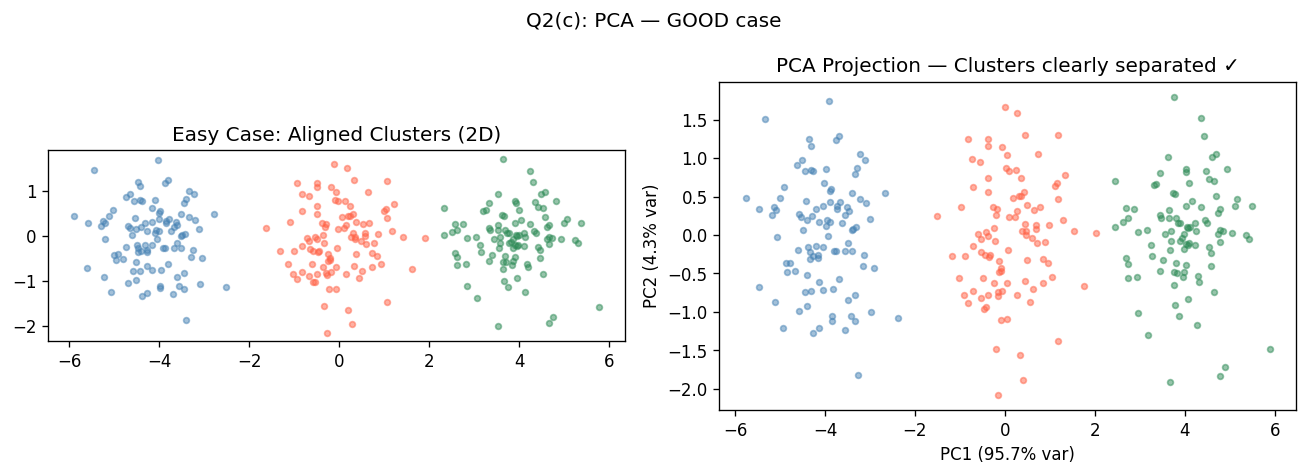

In [28]:
# Case 1: PCA works (aligned clusters) 
# Generate "easy" data: clusters along the x-axis

np.random.seed(0)
mu_easy = np.array([[-4, 0], [0, 0], [4, 0]])
sig_easy = np.array([[[0.5,0],[0,0.5]]]*3)
pi_easy  = np.array([1/3, 1/3, 1/3])
X_easy, labels_easy = sample_mog(pi_easy, mu_easy, sig_easy, 300)

pca_easy = PCA(n_components=2).fit(X_easy)
X_pca_easy = pca_easy.transform(X_easy)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k in range(3):
    m = labels_easy == k
    axes[0].scatter(X_easy[m,0], X_easy[m,1], s=12, alpha=0.5, color=colors[k])
axes[0].set_title('Easy Case: Aligned Clusters (2D)')
axes[0].set_aspect('equal')

for k in range(3):
    m = labels_easy == k
    axes[1].scatter(X_pca_easy[m,0], X_pca_easy[m,1], s=12, alpha=0.5, color=colors[k])
axes[1].set_title('PCA Projection — Clusters clearly separated ✓')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')

ev = pca_easy.explained_variance_ratio_
axes[1].set_xlabel(f'PC1 ({ev[0]*100:.1f}% var)')
axes[1].set_ylabel(f'PC2 ({ev[1]*100:.1f}% var)')
plt.suptitle('Q2(c): PCA — GOOD case', fontsize=12)
plt.tight_layout(); plt.show()

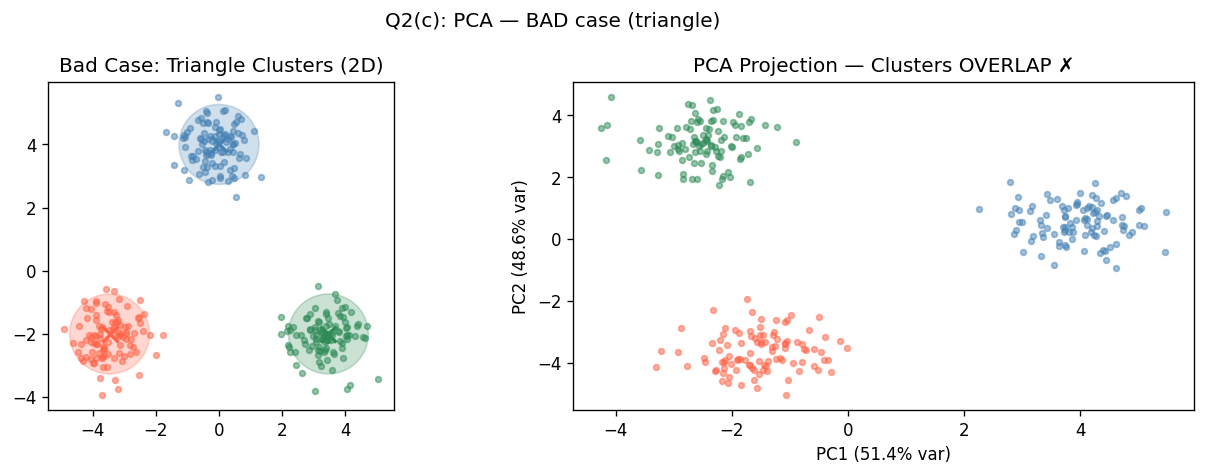

Explained variance ratios: [0.514 0.486]
→ PCA spreads variance equally — no discriminative PC exists


In [29]:
# Case 2: PCA fails (triangle arrangement) 
# Clusters at triangle vertices - symmetric, no dominant linear direction

np.random.seed(0)
r = 4.0
mu_tri = np.array([
    [r * np.cos(np.radians(90)),  r * np.sin(np.radians(90))],
    [r * np.cos(np.radians(210)), r * np.sin(np.radians(210))],
    [r * np.cos(np.radians(330)), r * np.sin(np.radians(330))],
])
sig_tri = np.array([[[0.4,0],[0,0.4]]]*3)
pi_tri  = np.array([1/3, 1/3, 1/3])
X_tri, labels_tri = sample_mog(pi_tri, mu_tri, sig_tri, 300)

pca_tri = PCA(n_components=2).fit(X_tri)
X_pca_tri = pca_tri.transform(X_tri)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k in range(3):
    m = labels_tri == k
    axes[0].scatter(X_tri[m,0], X_tri[m,1], s=12, alpha=0.5, color=colors[k])
    plot_gaussian_ellipse(axes[0], mu_tri[k], sig_tri[k], colors[k])
axes[0].set_title('Bad Case: Triangle Clusters (2D)')
axes[0].set_aspect('equal')

for k in range(3):
    m = labels_tri == k
    axes[1].scatter(X_pca_tri[m,0], X_pca_tri[m,1], s=12, alpha=0.5, color=colors[k])
ev = pca_tri.explained_variance_ratio_
axes[1].set_title('PCA Projection — Clusters OVERLAP ✗')
axes[1].set_xlabel(f'PC1 ({ev[0]*100:.1f}% var)')
axes[1].set_ylabel(f'PC2 ({ev[1]*100:.1f}% var)')

plt.suptitle('Q2(c): PCA — BAD case (triangle)', fontsize=12)
plt.tight_layout(); plt.show()

print("Explained variance ratios:", np.round(ev, 3))
print("→ PCA spreads variance equally — no discriminative PC exists")


### When PCA is a Good Model for MoG
**Scenario:** Clusters are arranged along a dominant linear axis, so between-cluster variance dominates in one direction. 

**Example:** Three components with means $[-4, 0]$, $[0, 0]$, $[4, 0]$ all aligned along $x_1$.

**Result:** PC1 captures **95.7%** of total variance. All three clusters are cleanly separated along PC1, with only 4.3% of variance in PC2 (within-cluster noise). A single principal component is sufficient to represent the full cluster structure. PCA succeeds because the direction of maximum variance coincides with the direction of cluster separation.

### When PCA is a Bad Model for MoG
**Scenario:** Clusters are arranged symmetrically, so no single linear direction separates all clusters simultaneously. 

**Example:** Three components placed at the vertices of an equilateral triangle: means at angles $90°$, $210°$, $330°$ from the origin at radius $r = 4$. 

**Result:** PC1 captures only **51.4%** of variance and PC2 captures **48.6%**: nearly equal. Green and red clusters occupy the same PC1 range ($-4$ to $-1$) and are only separated along PC2. No single projection axis separates all three clusters. PCA fails because the triangle arrangement is rotationally symmetric: variance is spread equally in all directions, so there is no discriminative principal component.

## Q2(c)(ii): Improving the Learning Procedure - Mixture of PPCA 

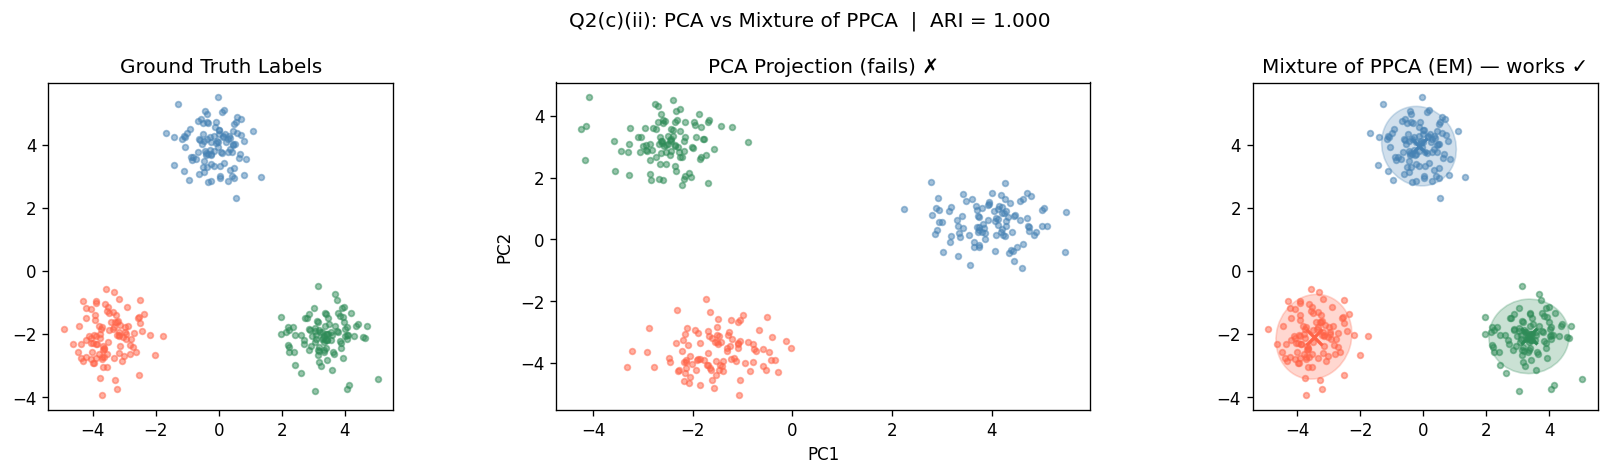

Mixture of PPCA — Adjusted Rand Index: 1.000  (1.0 = perfect)


In [30]:
# Fix: Mixture of PPCA on triangle case 
# Fit Mixture of PPCA (=GaussianMixture with full covariances) 

moppca = GaussianMixture(n_components=3, covariance_type='full',
                         n_init=10, random_state=42)
moppca.fit(X_tri)
moppca_labels = moppca.predict(X_tri)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Panel 1: true labels
for k in range(3):
    m = labels_tri == k
    axes[0].scatter(X_tri[m,0], X_tri[m,1], s=12, alpha=0.5, color=colors[k])
axes[0].set_title('Ground Truth Labels')
axes[0].set_aspect('equal')

# Panel 2: PCA (fails)
for k in range(3):
    m = labels_tri == k
    axes[1].scatter(X_pca_tri[m,0], X_pca_tri[m,1], s=12, alpha=0.5, color=colors[k])
axes[1].set_title('PCA Projection (fails) ✗')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')

# Panel 3: Mixture of PPCA (works)
# Algin predicted labels to true labels by majority vote 

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
conf = confusion_matrix(labels_tri, moppca_labels)
row_ind, col_ind = linear_sum_assignment(-conf)
label_map = {col_ind[i]: row_ind[i] for i in range(3)}
aligned = np.array([label_map[l] for l in moppca_labels])

for k in range(3):
    m = aligned == k
    axes[2].scatter(X_tri[m,0], X_tri[m,1], s=12, alpha=0.5, color=colors[k])
    plot_gaussian_ellipse(axes[2], moppca.means_[col_ind[k]],
                          moppca.covariances_[col_ind[k]], colors[k])
axes[2].set_title('Mixture of PPCA (EM) — works ✓')
axes[2].set_aspect('equal')

from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(labels_tri, aligned)
plt.suptitle(f'Q2(c)(ii): PCA vs Mixture of PPCA  |  ARI = {ari:.3f}', fontsize=12)
plt.tight_layout(); plt.show()

print(f"Mixture of PPCA — Adjusted Rand Index: {ari:.3f}  (1.0 = perfect)")


### Why PCA Fails Here

PCA fits a single global subspace to all data. For the triangle MoG, no single projection separates all three clusters, as shown by the green and red overlap along PC1 in panel 2.

### The Fix: Mixture of PPCA

Instead of one global subspace, **Mixture of PPCA** assigns each component its own local PPCA model. The full model is:

$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \, \mathbf{W}_k \mathbf{W}_k^\top + \sigma_k^2 \mathbf{I})$$

Each component $k$ has its own loading matrix $\mathbf{W}_k$ capturing local low-dimensional structure, and its own noise level $\sigma_k^2$. The full set of parameters $\{\pi_k, \boldsymbol{\mu}_k, \mathbf{W}_k, \sigma_k^2\}$ is learned jointly via EM: identical in structure to the MoG EM from Q2(b), with the PPCA likelihood replacing the plain Gaussian. 

In practice this is equivalent to `GaussianMixture` with `covariance_type='full'`, which learns a free covariance per component.

### Result

Panel 3 shows the recovered ellipses matching the ground truth positions exactly. ARI = 1.000 confirms every point was assigned to the correct cluster.

PCA fails because it is global and linear, so it is blind to cluster identity. Mixture of PPCA succeeds because each component models its own local geometry directly in the original space, without any global projection.